# 1. Exploratory Data Analysis (EDA)
In this notebook, we perform EDA on the EuroSAT and UC Merced datasets.
We will visualize:
- Class distribution
- Random samples
- Image sizes
- Pixel statistics (mean/std)
- Data Augmentations

In [1]:
import os
import sys
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter
from torchvision.datasets import ImageFolder
import torchvision.transforms as T

# Add project root to path
sys.path.append(str(Path.cwd().parent))

from configs.paths import EUROSAT_DIR, UCMERCED_DIR
from configs.config import IMAGE_SIZE
from data.dataset_loader import SatelliteDatasetLoader
from data.transforms import get_train_transforms, get_val_transforms

## 1. Verify and Load Dataset
First, we make sure the dataset is available (run `dataset_downloader.py` if not).

In [2]:
from data.dataset_downloader import download_eurosat, download_ucmerced

# Ensure datasets are downloaded
download_eurosat()
download_ucmerced()

# Load base datasets
eurosat_loader = SatelliteDatasetLoader(EUROSAT_DIR, split_type='random')
ucmerced_loader = SatelliteDatasetLoader(UCMERCED_DIR, split_type='random')

2026-07-19 09:53:47,616 - INFO - DatasetDownloader - Integrity check PASSED for D:\Main_Project_PeeyushVerma\data\datasets\eurosat\EuroSAT. Found 27000 images.
2026-07-19 09:53:47,617 - INFO - DatasetDownloader - EuroSAT already configured and verified at D:\Main_Project_PeeyushVerma\data\datasets\eurosat\EuroSAT. Skipping download.
2026-07-19 09:53:47,622 - INFO - DatasetDownloader - Integrity check PASSED for D:\Main_Project_PeeyushVerma\data\datasets\ucmerced. Found 2100 images.
2026-07-19 09:53:47,623 - INFO - DatasetDownloader - UC Merced already configured and verified at D:\Main_Project_PeeyushVerma\data\datasets\ucmerced. Skipping download.
2026-07-19 09:53:47,690 - INFO - DatasetLoader - Loaded dataset from D:\Main_Project_PeeyushVerma\data\datasets\eurosat\EuroSAT containing 27000 images across 10 classes.
2026-07-19 09:53:47,691 - INFO - DatasetLoader - Auto-resolved dataset loader root directory to nested folder: D:\Main_Project_PeeyushVerma\data\datasets\ucmerced\Images
20

## 2. Class Distribution

2026-07-19 09:53:47,711 - INFO - DatasetLoader - Dataset Statistics Summary: Total=27000, Classes=10


EuroSAT Statistics:


2026-07-19 09:53:48,812 - INFO - DataVisualization - Class distribution for EuroSAT:
2026-07-19 09:53:48,813 - INFO - DataVisualization -   - AnnualCrop: 3000
2026-07-19 09:53:48,814 - INFO - DataVisualization -   - Forest: 3000
2026-07-19 09:53:48,815 - INFO - DataVisualization -   - HerbaceousVegetation: 3000
2026-07-19 09:53:48,816 - INFO - DataVisualization -   - Highway: 2500
2026-07-19 09:53:48,816 - INFO - DataVisualization -   - Industrial: 2500
2026-07-19 09:53:48,817 - INFO - DataVisualization -   - Pasture: 2000
2026-07-19 09:53:48,817 - INFO - DataVisualization -   - PermanentCrop: 2500
2026-07-19 09:53:48,818 - INFO - DataVisualization -   - Residential: 3000
2026-07-19 09:53:48,818 - INFO - DataVisualization -   - River: 2500
2026-07-19 09:53:48,819 - INFO - DataVisualization -   - SeaLake: 3000


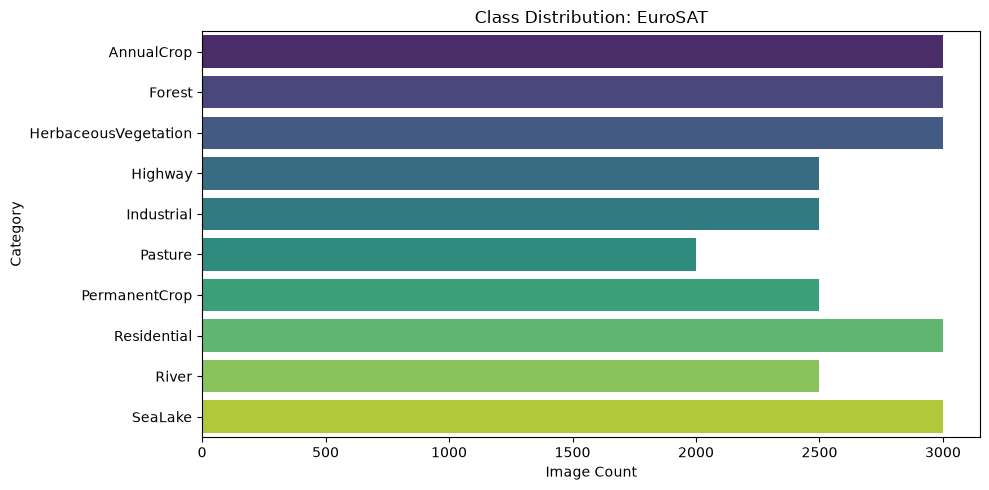

2026-07-19 09:53:49,423 - INFO - DatasetLoader - Dataset Statistics Summary: Total=2100, Classes=21
2026-07-19 09:53:49,427 - INFO - DataVisualization - Class distribution for Images:
2026-07-19 09:53:49,428 - INFO - DataVisualization -   - agricultural: 100
2026-07-19 09:53:49,428 - INFO - DataVisualization -   - airplane: 100
2026-07-19 09:53:49,430 - INFO - DataVisualization -   - baseballdiamond: 100
2026-07-19 09:53:49,430 - INFO - DataVisualization -   - beach: 100
2026-07-19 09:53:49,431 - INFO - DataVisualization -   - buildings: 100
2026-07-19 09:53:49,432 - INFO - DataVisualization -   - chaparral: 100
2026-07-19 09:53:49,432 - INFO - DataVisualization -   - denseresidential: 100
2026-07-19 09:53:49,433 - INFO - DataVisualization -   - forest: 100
2026-07-19 09:53:49,434 - INFO - DataVisualization -   - freeway: 100
2026-07-19 09:53:49,435 - INFO - DataVisualization -   - golfcourse: 100
2026-07-19 09:53:49,435 - INFO - DataVisualization -   - harbor: 100
2026-07-19 09:53:49,


UC Merced Statistics:


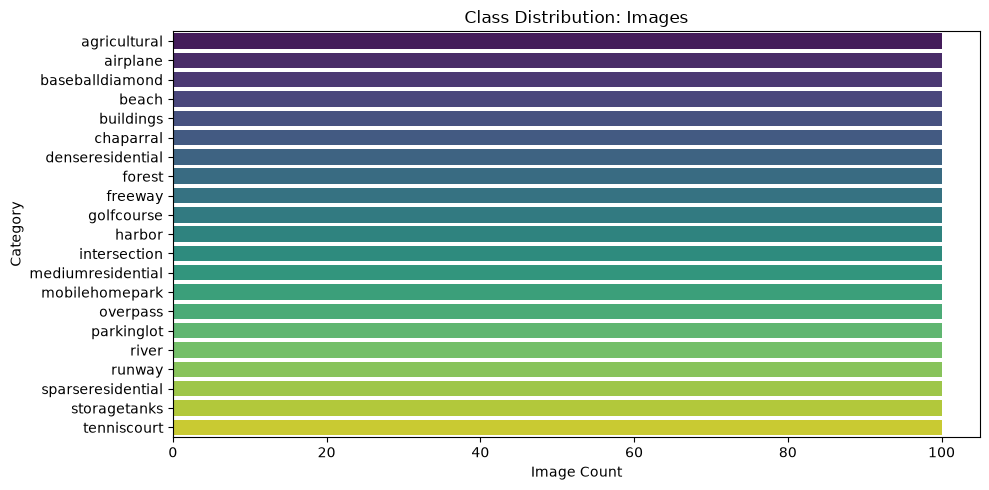

In [3]:
print("EuroSAT Statistics:")
eurosat_stats = eurosat_loader.generate_dataset_statistics()
eurosat_loader.plot_class_distribution()

print("\nUC Merced Statistics:")
ucmerced_stats = ucmerced_loader.generate_dataset_statistics()
ucmerced_loader.plot_class_distribution()

## 3. Sample Visualization

EuroSAT Random Samples:


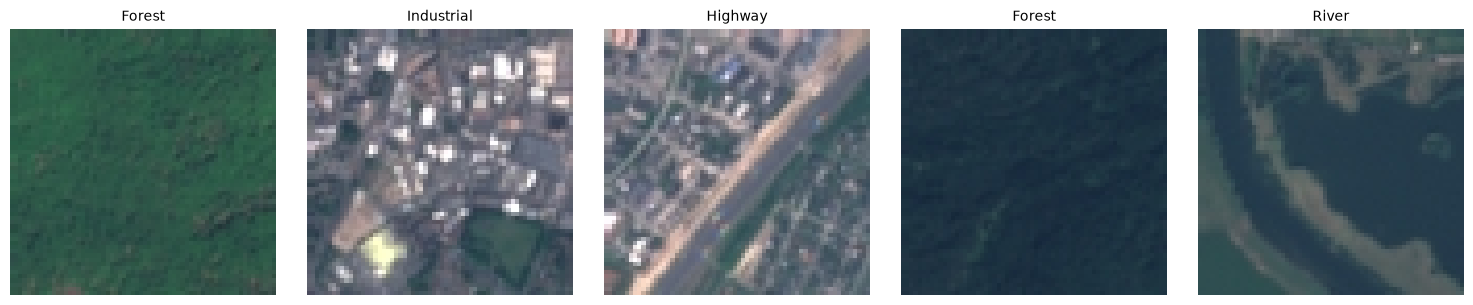

UC Merced Random Samples:


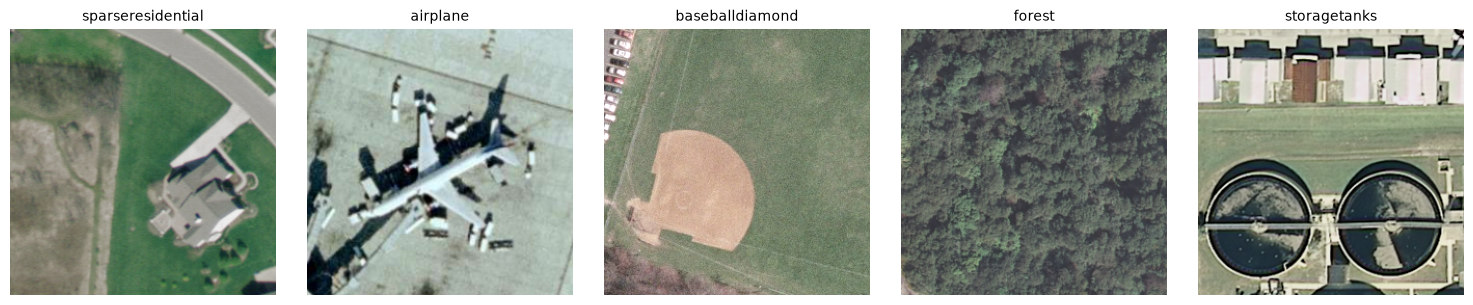

In [4]:
print("EuroSAT Random Samples:")
eurosat_loader.visualize_samples(num_samples=5)

print("UC Merced Random Samples:")
ucmerced_loader.visualize_samples(num_samples=5)

## 4. Image Size & Pixel Statistics
We calculate the mean and standard deviation of RGB channels.

In [5]:
from tqdm import tqdm
from PIL import Image

def calculate_pixel_stats(dataset_dir):
    img_paths = [os.path.join(root, f) for root, _, files in os.walk(dataset_dir) for f in files if f.endswith(('.jpg', '.png', '.tif'))]

    
    widths, heights = set(), set()
    pixel_sum = np.zeros(3)
    pixel_sq_sum = np.zeros(3)
    pixel_count = 0
    
    print(f"Processing {len(img_paths)} images...")
    for path in tqdm(img_paths[:5000]): # Limit to 5000 for speed in EDA
        img = Image.open(path).convert('RGB')
        w, h = img.size
        widths.add(w)
        heights.add(h)
        
        img_arr = np.array(img) / 255.0
        pixel_sum += img_arr.sum(axis=(0, 1))
        pixel_sq_sum += (img_arr ** 2).sum(axis=(0, 1))
        pixel_count += (w * h)
        
    mean = pixel_sum / pixel_count
    var = (pixel_sq_sum / pixel_count) - (mean ** 2)
    std = np.sqrt(var)
    
    print(f"Image Sizes - Width: {list(widths)}, Height: {list(heights)}")
    print(f"RGB Mean: {mean}")
    print(f"RGB Std: {std}")
    return mean, std

print("EuroSAT Pixel Stats:")
eurosat_mean, eurosat_std = calculate_pixel_stats(EUROSAT_DIR)

print("\nUC Merced Pixel Stats:")
ucmerced_mean, ucmerced_std = calculate_pixel_stats(UCMERCED_DIR)

EuroSAT Pixel Stats:
Processing 27000 images...


100%|██████████| 5000/5000 [00:03<00:00, 1656.85it/s]


Image Sizes - Width: [64], Height: [64]
RGB Mean: [0.36682955 0.38374722 0.39502432]
RGB Std: [0.25215096 0.14730863 0.11413674]

UC Merced Pixel Stats:
Processing 2100 images...


100%|██████████| 2100/2100 [00:07<00:00, 280.52it/s]

Image Sizes - Width: [256, 257, 242, 247, 249, 250, 252, 253, 254, 255], Height: [256, 257, 247, 249, 251, 253, 254, 255]
RGB Mean: [0.48421312 0.49003859 0.45048148]
RGB Std: [0.2180214  0.20207059 0.19583832]


## 5. Augmentations Visualization
Compare an original image with its augmented versions to see the effect of our data augmentation pipeline.

EuroSAT Augmentations:


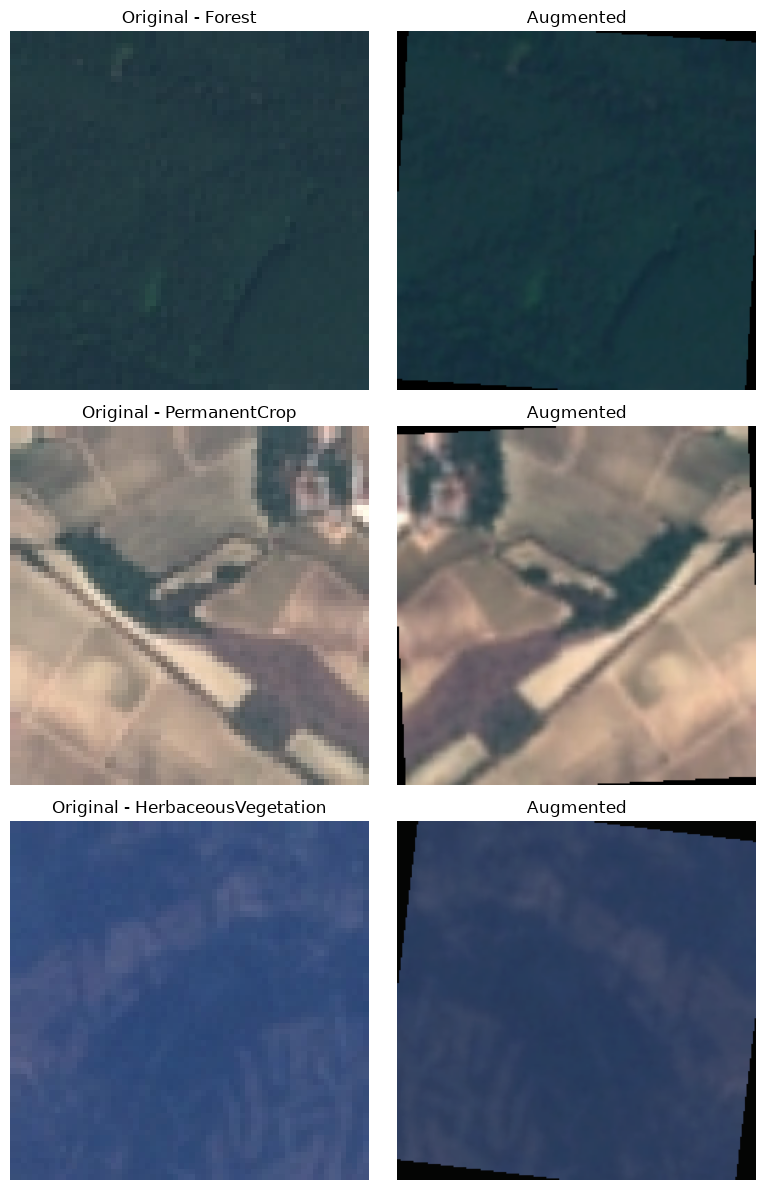

UC Merced Augmentations:


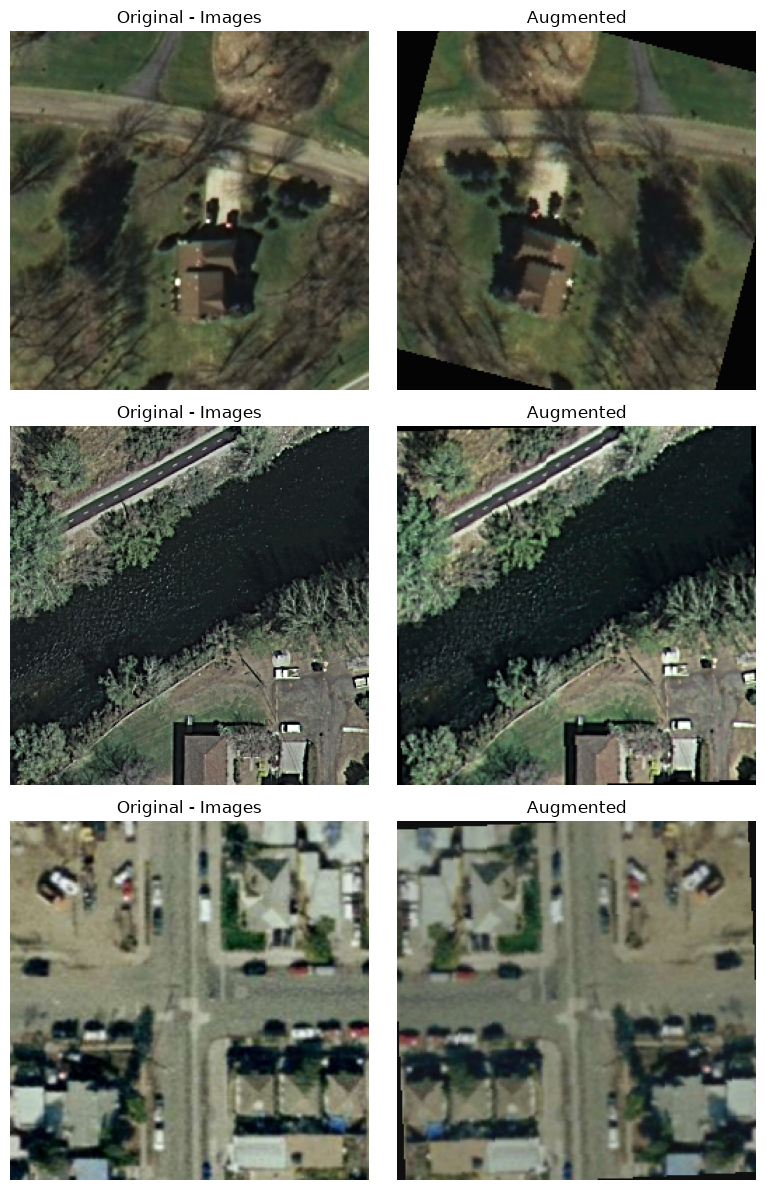

: 

In [ ]:
def visualize_augmentations(dataset_dir, num_examples=3):
    # Base dataset without augmentations
    base_ds = ImageFolder(root=dataset_dir)
    # Dataset with augmentations
    aug_ds = ImageFolder(root=dataset_dir, transform=get_train_transforms())
    
    indices = np.random.choice(len(base_ds), num_examples, replace=False)
    
    fig, axes = plt.subplots(num_examples, 2, figsize=(8, 4 * num_examples))
    if num_examples == 1:
        axes = np.expand_dims(axes, 0)
    
    # Helper to un-normalize augmented tensor
    inv_transform = T.Compose([
        T.Normalize(mean=[0., 0., 0.], std=[1/0.229, 1/0.224, 1/0.225]),
        T.Normalize(mean=[-0.485, -0.456, -0.406], std=[1., 1., 1.])
    ])

    for i, idx in enumerate(indices):
        # Original
        orig_img, label = base_ds[idx]
        axes[i, 0].imshow(orig_img)
        axes[i, 0].set_title(f"Original - {base_ds.classes[label]}")
        axes[i, 0].axis('off')
        
        # Augmented
        aug_tensor, _ = aug_ds[idx]
        aug_img = inv_transform(aug_tensor).permute(1, 2, 0).numpy()
        aug_img = np.clip(aug_img, 0, 1)
        axes[i, 1].imshow(aug_img)
        axes[i, 1].set_title("Augmented")
        axes[i, 1].axis('off')
        
    plt.tight_layout()
    plt.show()

print("EuroSAT Augmentations:")
visualize_augmentations(EUROSAT_DIR)

print("UC Merced Augmentations:")
visualize_augmentations(UCMERCED_DIR)
